# **Data Visualization**

## Import Library
Cell ini berfungsi untuk mempersiapkan dataset sebelum dilakukan visualisasi. Library Pandas digunakan untuk mengolah data, NumPy untuk mendukung operasi numerik, dan Matplotlib untuk membuat grafik.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Menghubungkan Google Colab ke Google Drive
Cell ini digunakan untuk memanggil data dari google drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Membaca dataset dari Google Drive
Cell ini untuk membaca dataset yang tersimpan di Google Drive sesuai dengan file_path yang dicantumkan

In [4]:
file_path = '/content/drive/MyDrive/DATA MINING/Bike Sharing Cleaned.xlsx'

df = pd.read_excel(file_path, engine='openpyxl')

print("Dataset berhasil dibaca!")
print("Jumlah baris dan kolom:", df.shape)
display(df.head())

Dataset berhasil dibaca!
Jumlah baris dan kolom: (731, 16)


,ID_Data,Tanggal,Musim,Tahun,mnth,Status_Libur,Hari,Status_Hari_Kerja,Kondisi_Cuaca,Suhu_Celsius,Suhu_Terasa_Celsius,Kelembapan_Persen,Kecepatan_Angin,Pengguna_Kasual,Pengguna_Terdaftar,Total_Penyewaan
0,1,2011-01-01,Musim Semi,2011,1,Bukan Hari Libur,Sabtu,Bukan Hari Kerja,Berkabut atau Berawan,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,2011-01-02,Musim Semi,2011,1,Bukan Hari Libur,Minggu,Bukan Hari Kerja,Berkabut atau Berawan,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,2011-01-03,Musim Semi,2011,1,Bukan Hari Libur,Senin,Hari Kerja,Cerah atau Berawan Ringan,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,2011-01-04,Musim Semi,2011,1,Bukan Hari Libur,Selasa,Hari Kerja,Cerah atau Berawan Ringan,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,2011-01-05,Musim Semi,2011,1,Bukan Hari Libur,Rabu,Hari Kerja,Cerah atau Berawan Ringan,9.305237,11.46350,43.6957,12.522300,82,1518,1600


## Memeriksa Dataset
Cell ini digunakan untuk mempersiapkan dataset penyewaan sepeda sebelum dilakukan analisis dan visualisasi data.

In [5]:
# Memastikan kolom tanggal menjadi format datetime
df["Tanggal"] = pd.to_datetime(df["Tanggal"], errors="coerce")

# Mengurutkan data berdasarkan tanggal
df = df.sort_values("Tanggal").reset_index(drop=True)

print("Dataset berhasil dibaca!")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Dataset berhasil dibaca!
Jumlah baris: 731
Jumlah kolom: 16


,ID_Data,Tanggal,Musim,Tahun,mnth,Status_Libur,Hari,Status_Hari_Kerja,Kondisi_Cuaca,Suhu_Celsius,Suhu_Terasa_Celsius,Kelembapan_Persen,Kecepatan_Angin,Pengguna_Kasual,Pengguna_Terdaftar,Total_Penyewaan
0,1,2011-01-01,Musim Semi,2011,1,Bukan Hari Libur,Sabtu,Bukan Hari Kerja,Berkabut atau Berawan,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,2011-01-02,Musim Semi,2011,1,Bukan Hari Libur,Minggu,Bukan Hari Kerja,Berkabut atau Berawan,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,2011-01-03,Musim Semi,2011,1,Bukan Hari Libur,Senin,Hari Kerja,Cerah atau Berawan Ringan,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,2011-01-04,Musim Semi,2011,1,Bukan Hari Libur,Selasa,Hari Kerja,Cerah atau Berawan Ringan,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,2011-01-05,Musim Semi,2011,1,Bukan Hari Libur,Rabu,Hari Kerja,Cerah atau Berawan Ringan,9.305237,11.46350,43.6957,12.522300,82,1518,1600


## Membuat kolom periode dan agregasi bulanan

Cell ini berfungsi untuk mengelompokkan data penyewaan sepeda berdasarkan periode bulan menggunakan fungsi groupby(). Fungsi agg() digunakan untuk menjumlahkan total penyewaan, pengguna kasual, dan pengguna terdaftar pada setiap bulan. Hasil agregasi digunakan sebagai dasar pembuatan grafik tren bulanan sehingga perubahan jumlah penyewaan dapat diamati dengan lebih mudah.

In [6]:
# Membuat kolom periode bulanan
df["Periode_Bulan"] = df["Tanggal"].dt.to_period("M")

# Mengelompokkan data berdasarkan bulan
data_bulanan = (
    df.groupby("Periode_Bulan")
      .agg({
          "Total_Penyewaan": "sum",
          "Pengguna_Kasual": "sum",
          "Pengguna_Terdaftar": "sum"
      })
      .reset_index()
)

# Mengubah periode menjadi teks untuk sumbu grafik
data_bulanan["Periode_Bulan"] = (
    data_bulanan["Periode_Bulan"].astype(str)
)

print("Agregasi data bulanan berhasil dibuat")
display(data_bulanan.head())

Agregasi data bulanan berhasil dibuat


,Periode_Bulan,Total_Penyewaan,Pengguna_Kasual,Pengguna_Terdaftar
0,2011-01,38189,3073,35116
1,2011-02,48215,6242,41973
2,2011-03,64045,12826,51219
3,2011-04,94870,22346,72524
4,2011-05,135821,31050,104771


## Visualisasi penyewaan bulanan


Cell ini berfungsi untuk menampilkan perubahan total penyewaan sepeda dari bulan ke bulan menggunakan *line chart*. Sumbu X menunjukkan periode bulan, sedangkan sumbu Y menunjukkan total penyewaan sepeda. Pengaturan ukuran grafik, judul, label sumbu, warna garis, marker, dan grid dilakukan agar grafik lebih mudah dibaca. Anotasi ditambahkan untuk memberikan informasi mengenai nilai penyewaan tertinggi selama periode pengamatan.

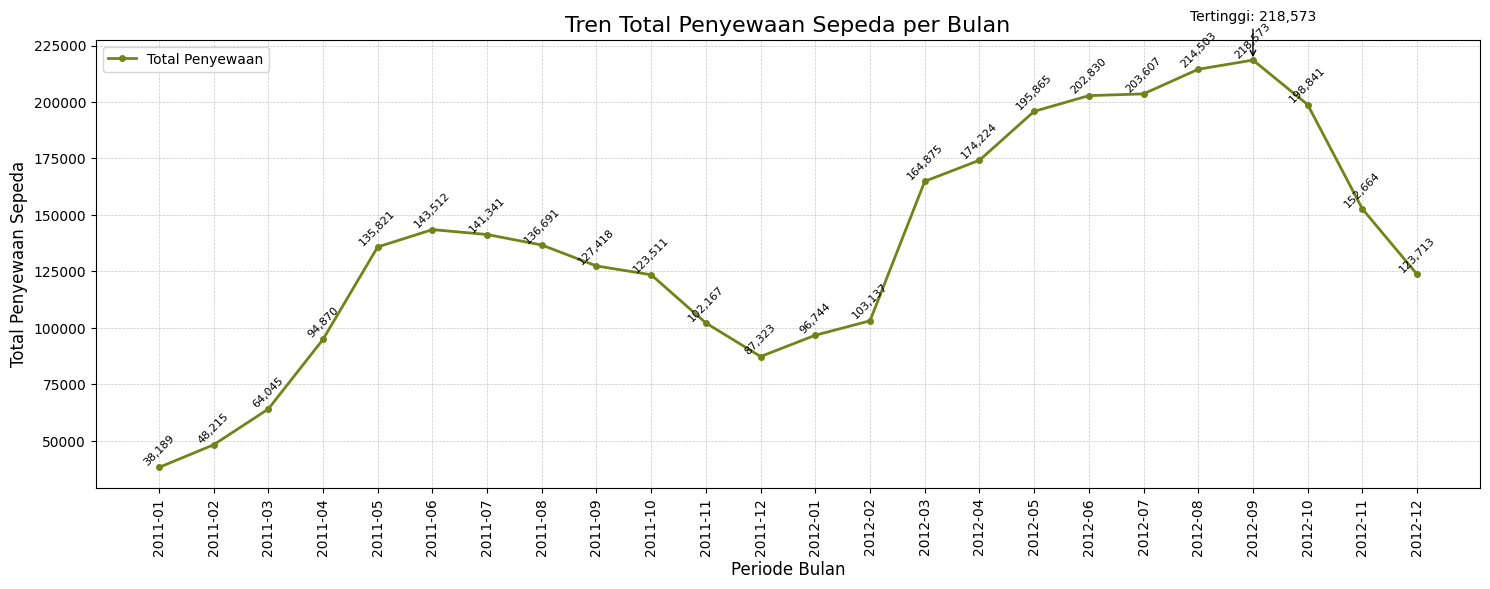

In [24]:

plt.figure(figsize=(15, 6))

plt.plot(
    data_bulanan["Periode_Bulan"],
    data_bulanan["Total_Penyewaan"],
    color="#708419",
    linewidth=2,
    linestyle="-",
    marker="o",
    markersize=4,
    label="Total Penyewaan" )

# Menampilkan angka pada setiap titik grafik
for i, nilai in enumerate(data_bulanan["Total_Penyewaan"]):
    plt.text(
        i,
        nilai,
        f"{nilai:,.0f}",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=45    )

plt.title("Tren Total Penyewaan Sepeda per Bulan", fontsize=16)
plt.xlabel("Periode Bulan", fontsize=12)
plt.ylabel("Total Penyewaan Sepeda", fontsize=12)

plt.xticks(
    ticks=range(len(data_bulanan)),
    labels=data_bulanan["Periode_Bulan"],
    rotation=90 )

plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
plt.legend()

# Menambahkan anotasi pada bulan dengan penyewaan tertinggi
idx = data_bulanan["Total_Penyewaan"].idxmax()
bulan = data_bulanan.loc[idx, "Periode_Bulan"]
nilai = data_bulanan.loc[idx, "Total_Penyewaan"]

plt.annotate(
    f"Tertinggi: {nilai:,.0f}",
    xy=(idx, nilai),
    xytext=(idx, nilai * 1.08),
    ha="center",
    arrowprops=dict(arrowstyle="->") )

plt.tight_layout()
plt.show()


## Visualisasi penyewaan berdasarkan hari
Cell ini berfungsi untuk membandingkan total penyewaan sepeda berdasarkan hari dalam seminggu menggunakan bar chart. Data dikelompokkan berdasarkan nama hari, kemudian total penyewaan setiap hari dijumlahkan. Urutan hari diatur mulai dari Senin hingga Minggu agar hasil grafik lebih terstruktur. Grafik ini membantu mengetahui hari dengan total penyewaan tertinggi dan terendah.

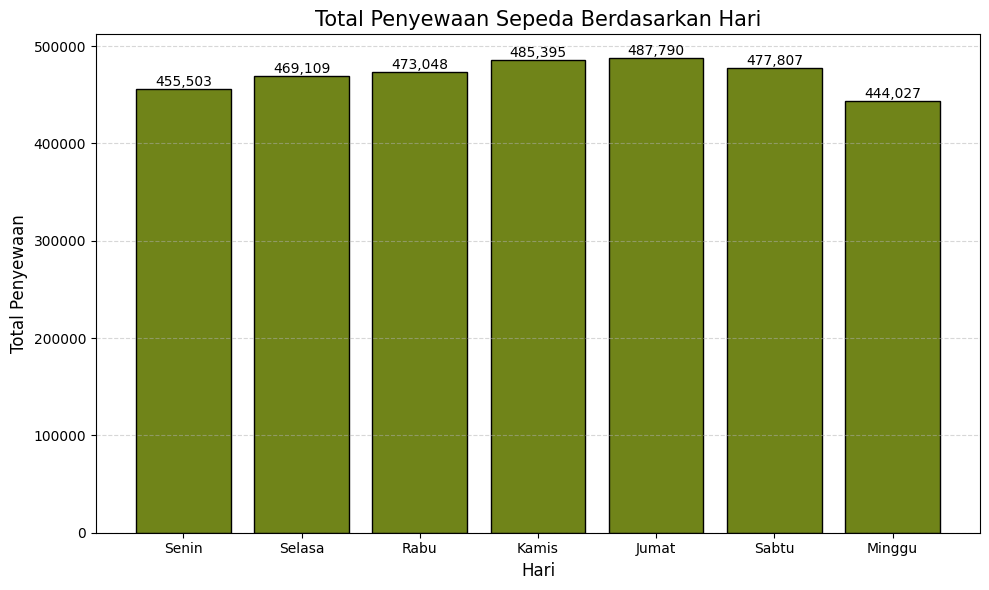

In [25]:

# Menghitung total penyewaan setiap hari
data_harian = (
    df.groupby("Hari")["Total_Penyewaan"]
      .sum()  )

# Mengatur urutan hari jika label menggunakan bahasa Indonesia
urutan_hari = [
    "Senin", "Selasa", "Rabu", "Kamis",
    "Jumat", "Sabtu", "Minggu"  ]

data_harian = data_harian.reindex(urutan_hari).dropna()

plt.figure(figsize=(10, 6))
plt.bar(
    data_harian.index,
    data_harian.values,
    color="#708419",
    edgecolor="black" )

# Menampilkan angka pada setiap batang grafik
for i, nilai in enumerate(data_harian.values):
    plt.text(
        i,
        nilai,
        f"{nilai:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10     )

plt.title("Total Penyewaan Sepeda Berdasarkan Hari", fontsize=15)
plt.xlabel("Hari", fontsize=12)
plt.ylabel("Total Penyewaan", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## Visualisasi pengguna kasual dan terdaftar
Cell ini berfungsi untuk membandingkan total penyewaan sepeda oleh pengguna kasual dan pengguna terdaftar. Jumlah penyewaan dari masing-masing kategori dihitung menggunakan fungsi sum()

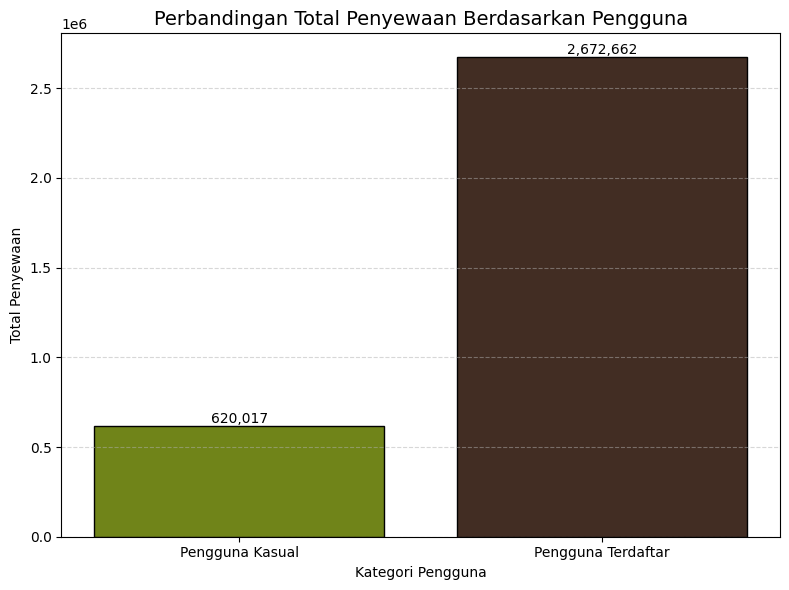

In [23]:
kategori_pengguna = [
    "Pengguna Kasual",
    "Pengguna Terdaftar"  ]

total_pengguna = [
    df["Pengguna_Kasual"].sum(),
    df["Pengguna_Terdaftar"].sum()  ]

plt.figure(figsize=(8, 6))
plt.bar(
    kategori_pengguna,
    total_pengguna,
    color=["#708419", "#422d23"],
    edgecolor="black"   )

plt.title("Perbandingan Total Penyewaan Berdasarkan Pengguna", fontsize=14)
plt.xlabel("Kategori Pengguna")
plt.ylabel("Total Penyewaan")
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Menampilkan nilai di atas batang
for i, nilai in enumerate(total_pengguna):
    plt.text(
        i, nilai, f"{nilai:,.0f}",
        ha="center", va="bottom"    )

plt.tight_layout()
plt.show()

## Visualisasi hubungan suhu dengan penyewaan
Cell ini berfungsi untuk mengamati hubungan antara suhu udara dan total penyewaan sepeda menggunakan scatter plot. Sumbu X menunjukkan suhu dalam derajat Celsius, sedangkan sumbu Y menunjukkan total penyewaan sepeda setiap hari. Setiap titik merepresentasikan satu data harian.

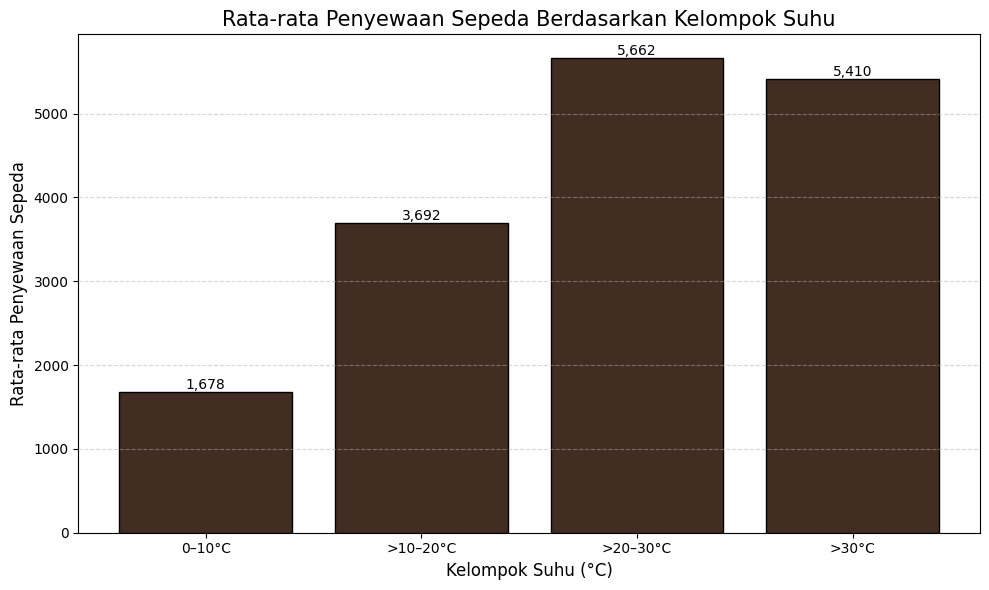

In [18]:
# Membuat kategori suhu
batas_suhu = [0, 10, 20, 30, 50]
label_suhu = [
    "0–10°C",
    ">10–20°C",
    ">20–30°C",
    ">30°C"  ]
df["Kelompok_Suhu"] = pd.cut(
    df["Suhu_Celsius"],
    bins=batas_suhu,
    labels=label_suhu,
    right=True,
    include_lowest=True  )

# Menghitung rata-rata penyewaan pada setiap kelompok suhu
data_suhu = (
    df.groupby("Kelompok_Suhu", observed=False)["Total_Penyewaan"]
      .mean()
      .dropna()  )

# Membuat diagram batang
plt.figure(figsize=(10, 6))
plt.bar(
    data_suhu.index.astype(str),
    data_suhu.values,
    color="#422d23",
    edgecolor="black"  )

plt.title(
    "Rata-rata Penyewaan Sepeda Berdasarkan Kelompok Suhu",
    fontsize=15  )
plt.xlabel("Kelompok Suhu (°C)", fontsize=12)
plt.ylabel("Rata-rata Penyewaan Sepeda", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Menampilkan nilai di atas setiap batang
for i, nilai in enumerate(data_suhu.values):
    plt.text(
        i,
        nilai,
        f"{nilai:,.0f}",
        ha="center",
        va="bottom"    )

plt.tight_layout()
plt.show()

## Visualisasi Penyewaan berdasarkan kondisi cuaca
Cell ini berfungsi untuk membandingkan total penyewaan sepeda pada berbagai kondisi cuaca, data dikelompokkan berdasarkan kategori kondisi cuaca, kemudian total penyewaan setiap kategori dijumlahkan dan diurutkan dari nilai terbesar ke terkecil. Grafik ini membantu mengamati perbedaan total penyewaan pada setiap kategori cuaca, dengan mempertimbangkan bahwa jumlah hari pada setiap kategori mungkin berbeda.

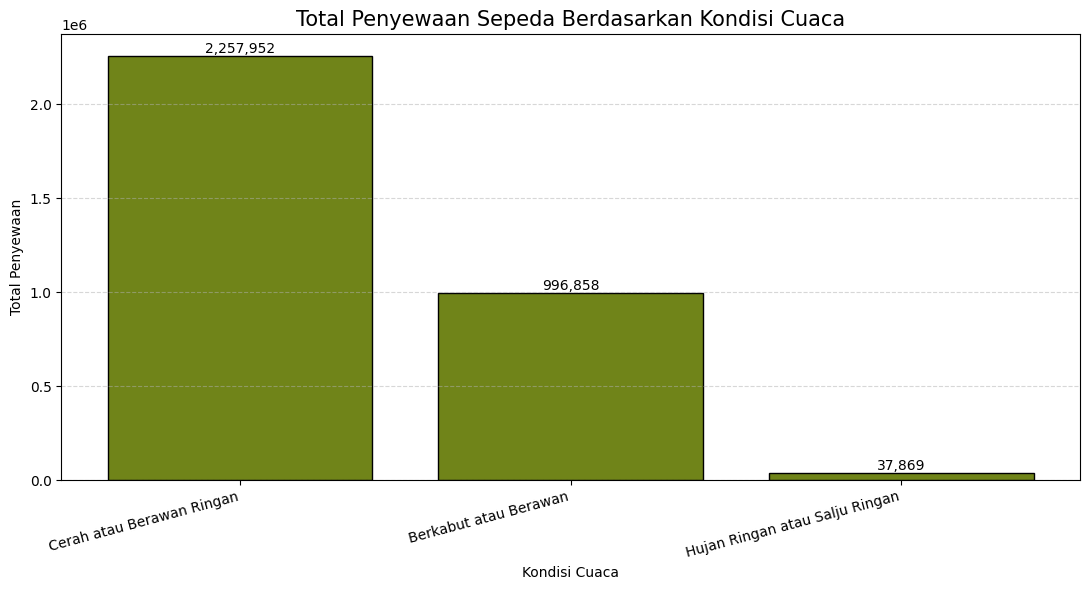

In [26]:

data_cuaca = (
    df.groupby("Kondisi_Cuaca")["Total_Penyewaan"]
      .sum()
      .sort_values(ascending=False) )

plt.figure(figsize=(11, 6))
plt.bar(
    data_cuaca.index,
    data_cuaca.values,
    color="#708419",
    edgecolor="black"  )

# Menampilkan angka pada setiap batang grafik
for i, nilai in enumerate(data_cuaca.values):
    plt.text(
        i,
        nilai,
        f"{nilai:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10    )

plt.title("Total Penyewaan Sepeda Berdasarkan Kondisi Cuaca", fontsize=15)
plt.xlabel("Kondisi Cuaca")
plt.ylabel("Total Penyewaan")

plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## Ringkasan Statistik

In [15]:
print("RINGKASAN DATA PENYEWAAN SEPEDA")
print("=" * 40)

print("Jumlah data:", len(df))
print("Total penyewaan:", f"{df['Total_Penyewaan'].sum():,}")
print("Rata-rata penyewaan harian:",
      f"{df['Total_Penyewaan'].mean():,.2f}")

idx_max = df["Total_Penyewaan"].idxmax()
idx_min = df["Total_Penyewaan"].idxmin()

print("\nTanggal penyewaan tertinggi:",
      df.loc[idx_max, "Tanggal"].strftime("%d-%m-%Y"))
print("Jumlah:", f"{df.loc[idx_max, 'Total_Penyewaan']:,}")

print("\nTanggal penyewaan terendah:",
      df.loc[idx_min, "Tanggal"].strftime("%d-%m-%Y"))
print("Jumlah:", f"{df.loc[idx_min, 'Total_Penyewaan']:,}")

print("\nTotal pengguna kasual:",
      f"{df['Pengguna_Kasual'].sum():,}")
print("Total pengguna terdaftar:",
      f"{df['Pengguna_Terdaftar'].sum():,}")

RINGKASAN DATA PENYEWAAN SEPEDA
Jumlah data: 731
Total penyewaan: 3,292,679
Rata-rata penyewaan harian: 4,504.35

Tanggal penyewaan tertinggi: 15-09-2012
Jumlah: 8,714

Tanggal penyewaan terendah: 29-10-2012
Jumlah: 22

Total pengguna kasual: 620,017
Total pengguna terdaftar: 2,672,662
